# Linear Regression using Gradient Descent

## Linear Regression by implementing of gradient descent algorithm

The linear regression line is defined as $$y = \theta_0 + \theta_1 x $$

The parameters $\theta_0$ and $\theta_1$ can be computed using gradeint descent algorithm.

Gradeint descent algorithm is given as:


repeat until convergence {
\begin{align*}
    \theta_1 &= \theta_1 - \alpha \frac{1}{m}\sum_{i=1}^{m} \big ( h_\theta (x^{(i)}) - y^{(i)} \big ) * x^{(i)} \\
    \theta_0 &= \theta_0 - \alpha \frac{1}{m}\sum_{i=1}^{m} \big ( h_\theta (x^{(i)}) - y^{(i)} \big )
\end{align*}
}

Reference: https://towardsdatascience.com/

### Step 1: Import libraries and dataset

In [1]:
## Import all the necessary libraries

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline


In [2]:
## Import the dataset
data = pd.read_csv('salary_data.csv')
# the CSV sits next to this notebook; change the path as necessary
X = data.iloc[:, 0].values   # plain numpy arrays: fast, no index alignment surprises
Y = data.iloc[:, 1].values
# View the size of the arrays X and Y
print(X.shape)
print(Y.shape)

(30,)
(30,)


### Step 2: EDA , Preprocessing , Create the training data

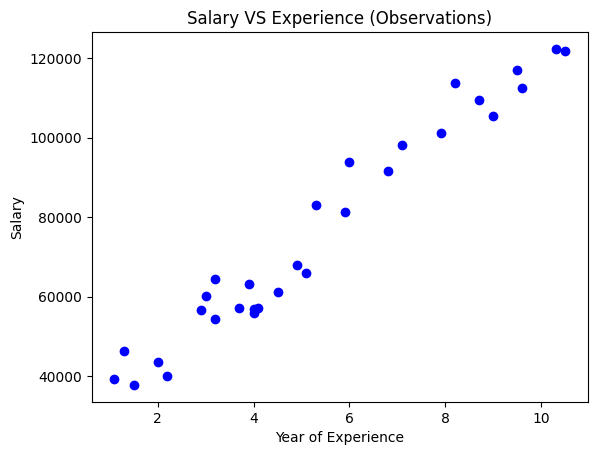

In [3]:
# Visualize the dataset

plt.scatter(X, Y, color='blue')
plt.title('Salary VS Experience (Observations)')
plt.xlabel('Year of Experience')
plt.ylabel('Salary')
plt.show()

In [4]:
# Split the data into train vs test set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

#### Feature scaling

Gradient descent on raw `X` (years, 1 to 11) with a learning rate small enough to be stable for the huge `Y` scale
(salaries ~ 10^4 to 10^5) converges extremely slowly, so after 10000 epochs it is still far from the optimum.
We **standardise X** using the *training* mean and standard deviation only (no information from the test set):

$$x_s = \frac{x - \mu_{train}}{\sigma_{train}}$$

The model is learnt in the scaled space; at the end we convert $\theta$ back to original units.

In [5]:
# Standardise X with TRAIN statistics only
x_mean, x_std = X_train.mean(), X_train.std()
X_train_s = (X_train - x_mean) / x_std
X_test_s  = (X_test  - x_mean) / x_std

### Step 3: Train the machine learning model

In [6]:
# Build the model
theta1 = 0
theta0 = 0
alpha = 0.1     # Learning Rate (fine because X is standardised)
epochs = 1000   # Number of iterations to perform gradient descent
m = float(len(X_train_s))   # Number of training examples
m_test = float(len(X_test_s))
cost_history = []
cost_onTestData_history = []
# Performing Gradient Descent
for i in range(epochs):
    Y_pred = theta1 * X_train_s + theta0
    # gradients of J = 1/(2m) * sum((h - y)^2)
    temp1 = (-1/m) * np.sum(X_train_s * (y_train - Y_pred))
    temp0 = (-1/m) * np.sum(y_train - Y_pred)
    theta1 = theta1 - alpha * temp1
    theta0 = theta0 - alpha * temp0
    # cost AFTER the update, so cost_history[i] belongs to the theta we just computed
    # NB: 1/(2*m), not 1/2*m (which would be m/2). Test cost uses the TEST set size.
    costTrain = (1/(2*m)) * np.sum((y_train - (theta1 * X_train_s + theta0))**2)
    costTest = (1/(2*m_test)) * np.sum((y_test - (theta1 * X_test_s + theta0))**2)
    cost_history.append(costTrain)
    cost_onTestData_history.append(costTest)

### Step 4: Visualize the results

In [7]:
# The coefficients (in the standardised-X space)
print('Theta1 (scaled X) = ', theta1)
print('Theta0 (scaled X) = ', theta0)

# Convert back to the original units of X:  y = theta0 + theta1*(x - mu)/sigma
theta1_orig = theta1 / x_std
theta0_orig = theta0 - theta1 * x_mean / x_std
print('Theta1 (original X) = ', theta1_orig)
print('Theta0 (original X) = ', theta0_orig)

# Sanity check: closed-form least squares (normal equation) should give the same numbers
ols_theta1, ols_theta0 = np.polyfit(X_train, y_train, 1)
print('OLS    Theta1 = ', ols_theta1, ' Theta0 = ', ols_theta0)

Theta1 (scaled X) =  27151.537425833663
Theta0 (scaled X) =  74207.62499999994
Theta1 (original X) =  9423.81532303097
Theta0 (original X) =  25321.583011776784
OLS    Theta1 =  9423.815323030976  Theta0 =  25321.583011776787


### Step 5: Prediction

In [8]:
# Predict the values for the TRAINING X (cells below depend on this Y_pred)
Y_pred = theta1 * X_train_s + theta0
Y_pred

array([122386.880839  , 107308.77632215,  63016.8443039 ,  35687.77986711,
        46053.97672244,  73383.04115923,  52650.64744857,  63959.2258362 ,
        63016.8443039 ,  99769.72406372,  37572.54293172,  39457.30599632,
       110135.92091906,  44169.21365784,  92230.6718053 , 114847.82858057,
        80922.09341766, 124271.6439036 ,  89403.52720839,  55477.79204548,
        62074.4627716 ,  67728.75196542,  81864.47494996,  53593.02898087])

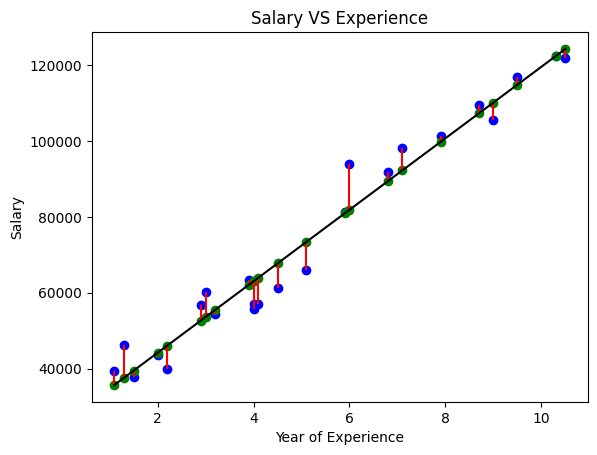

In [9]:
# Visualize the dataset and plot the residuals

fig, ax = plt.subplots()

ax.scatter(X_train, y_train, color='blue')       # observed values
ax.scatter(X_train, Y_pred, color='green') # predicted values
ax.vlines(X_train,y_train, Y_pred, color='red')  # residual lines
plt.plot([min(X_train), max(X_train)], [min(Y_pred), max(Y_pred)], color='black')  # regression line

plt.title('Salary VS Experience')
plt.xlabel('Year of Experience')
plt.ylabel('Salary')
plt.show()

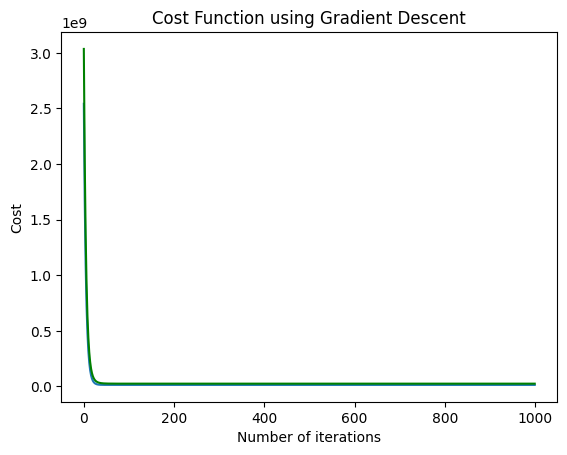

In [10]:
# plot the cost function

plt.plot(cost_history)
plt.plot(cost_onTestData_history, color="green")
plt.title('Cost Function using Gradient Descent')
plt.xlabel("Number of iterations")
plt.ylabel("Cost")
plt.show()

### Step 6: Model Evalaution & Assessment using Performance measures

In [11]:
from sklearn.metrics import mean_squared_error, r2_score
print("Performance on Training Set")
# The mean squared error
print("Mean squared error = %.2f" % mean_squared_error(y_train, Y_pred))

# Explained variance score: 1 is perfect prediction
print('R2 score = %.2f' % r2_score(y_train, Y_pred))

Performance on Training Set
Mean squared error = 27102249.73
R2 score = 0.96


In [12]:
# Predict the values for the test data
Y_Test_pred = theta1 * X_test_s + theta0
print("Performance on Test Set")
# The mean squared error
print("Mean squared error = %.2f" % mean_squared_error(y_test, Y_Test_pred))

# Explained variance score: 1 is perfect prediction
print('R2 score = %.2f' % r2_score(y_test, Y_Test_pred))

Performance on Test Set
Mean squared error = 49830096.86
R2 score = 0.90
